In [2]:
from specml.data import SpectroscopicData
from specml.visualization import plotting
from specml.processing.masking import create_mask_from_area, apply_mask, rebuild_tissue_mask
from specml.processing.preprocessing import vector_norm, adjust_spectra_min_to_zero
import numpy as np

In [4]:
test_data = SpectroscopicData(file_path=f'D:/Lung_Data_8cm/6F-6504-01/6F-6504-01_top2/6f-6504-01_top2.dmt', inplace=True)

INFO:specml.data.loaders:Data loaded from D:/Lung_Data_8cm/6F-6504-01/6F-6504-01_top2/6f-6504-01_top2.dmt with shape (512, 1664, 754)
INFO:specml.data.spectroscopic_data:Data flattened and mask applied. Shape of processed data: (851968, 754)
INFO:specml.data.spectroscopic_data:{'filename': 'D:/Lung_Data_8cm/6F-6504-01/6F-6504-01_top2/6f-6504-01_top2.dmt', 'xpixels': 1664, 'ypixels': 512, 'xtiles': 13, 'ytiles': 4, 'numpts': 754, 'fpasize': 128, 'original_shape': (512, 1664, 754)}


In [5]:

# test_data.easy_preprocess(deriv=0, area_threshold=3.5)
test_data.keep_range(1000,1800)
test_data.adjust_min_to_zero()
test_data.normalize()
test_data.data.shape


INFO:specml.data.spectroscopic_data:Kept wavenumber range from 1000 to 1800


(851968, 206)

Data is flattened. Reshaping it back to 3D.


INFO:specml.data.spectroscopic_data:Data reshaped back to 3D with shape (512, 1664, 206)


Image slice shape: (512, 1664)


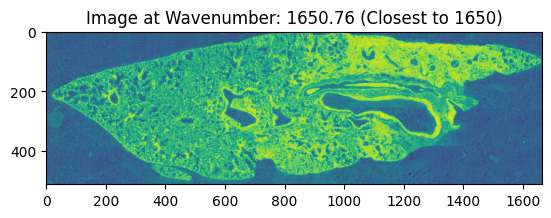

In [6]:
plotting.plot_image_over_wavenumber(test_data, target_wavenumber=1650, )

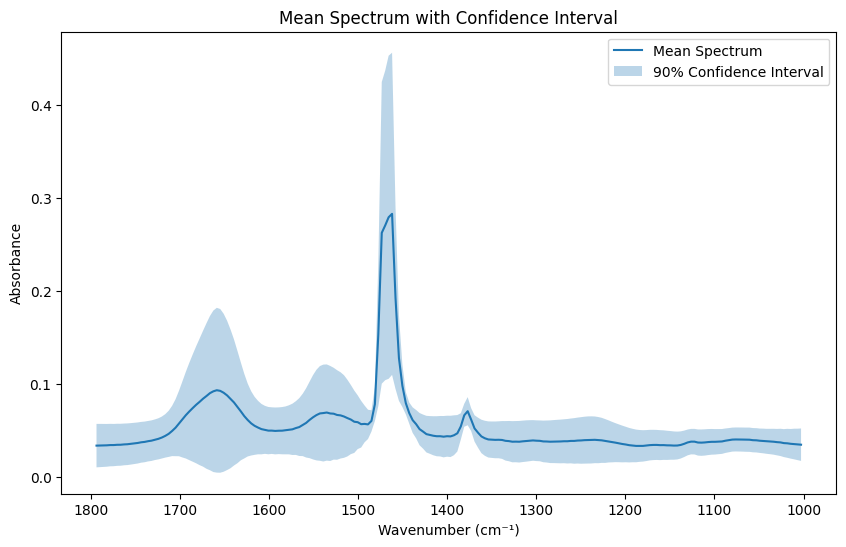

INFO:specml.data.spectroscopic_data:Data reshaped back to 3D with shape (512, 1664, 206)
INFO:specml.data.spectroscopic_data:Data reshaped back to 3D with shape (512, 1664, 206)
INFO:specml.data.spectroscopic_data:Data reshaped back to 3D with shape (512, 1664, 206)


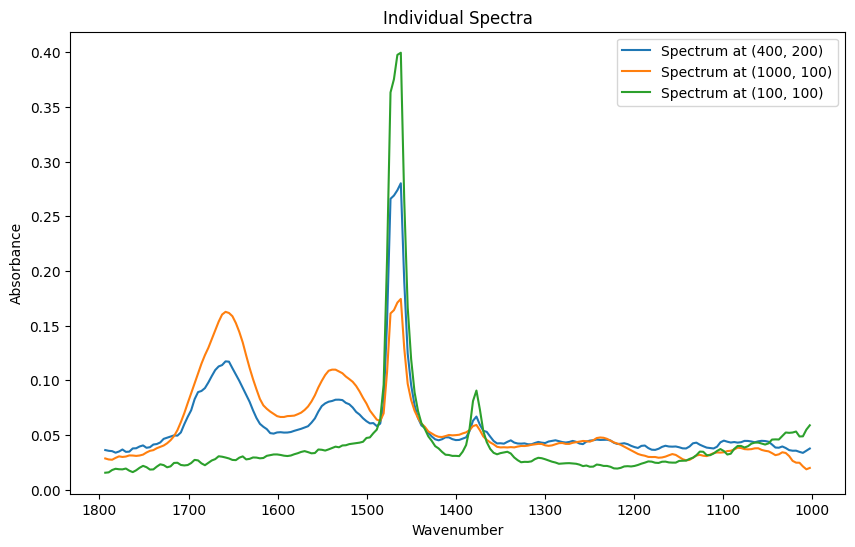

In [7]:
# plotting.plot_image_over_wavenumber(test_data, target_wavenumber=1400)
plotting.plot_mean_spectrum_with_confidence_interval(test_data)
# plotting.plot_value_distribution(test_data.data[:,100], bins=30)
# plotting.plot_area_map(test_data, 1600, 1700)
plotting.plot_individual_spectra(test_data, [(400,200),(1000,100),(100,100)])


In [8]:
from specml.feature_engineering.dim_reduction import apply_pca

pca_result = apply_pca(test_data, n_components=3)

c:\Users\u37314kd\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


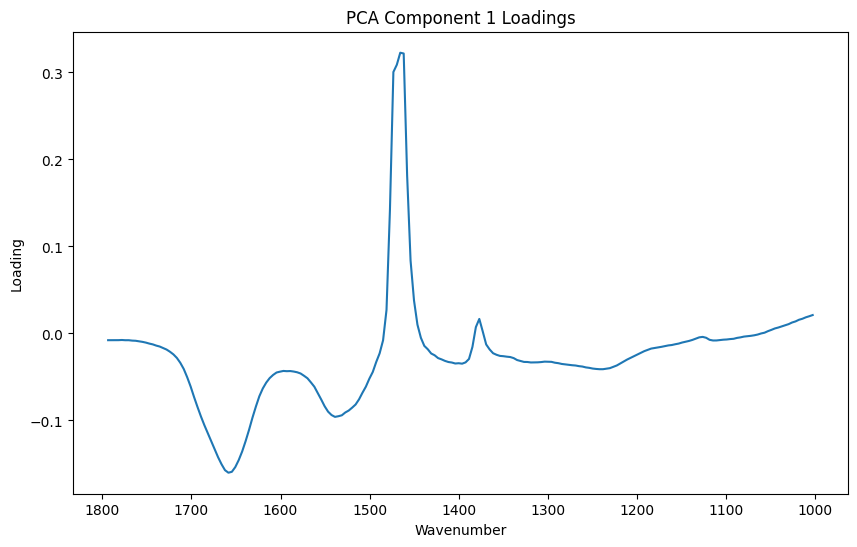

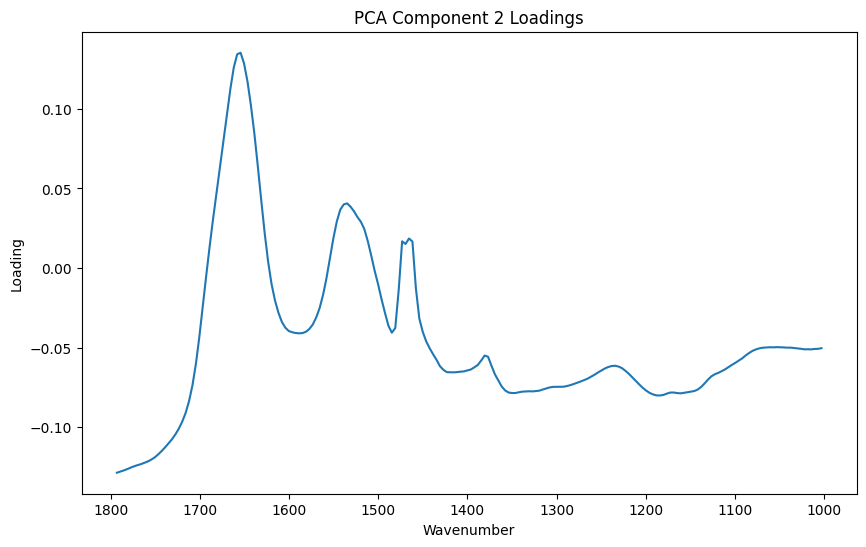

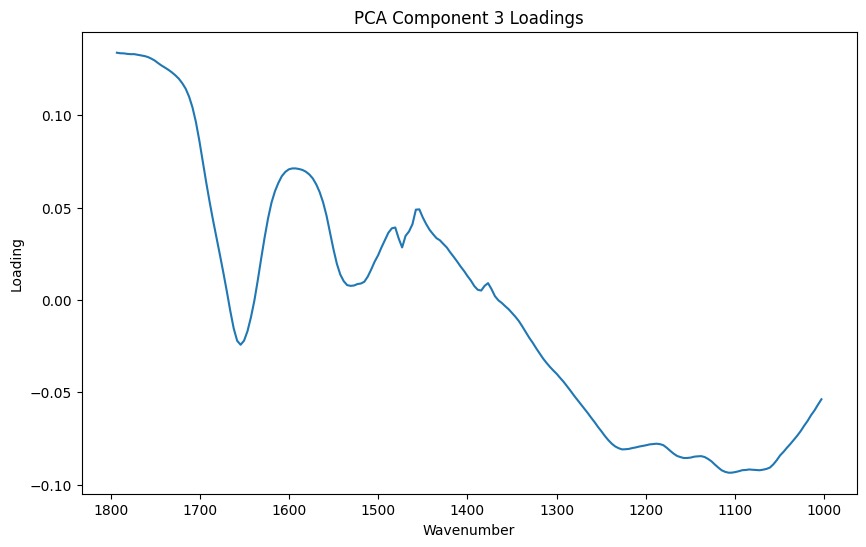

In [9]:
plotting.plot_pca_loadings(pca_result, component=1)
plotting.plot_pca_loadings(pca_result, component=2)
plotting.plot_pca_loadings(pca_result, component=3)

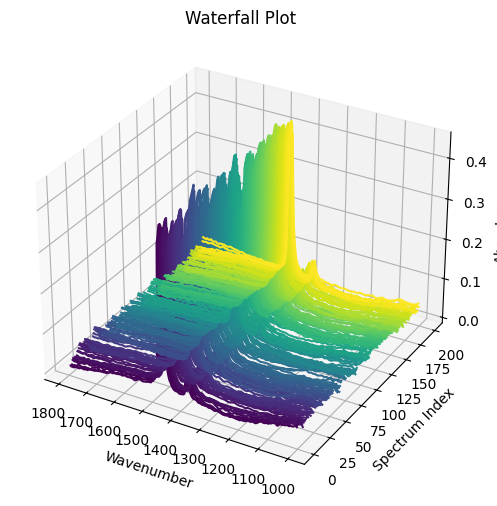

In [10]:
plotting.plot_waterfall(test_data)